In [1]:
# acquire MNIST data through Keras API
from tensorflow.keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

# reshape (flatten) data before PCA
import numpy as np

train_images = np.reshape(train_images, (-1, 784))
test_images = np.reshape(test_images, (-1, 784))

Text(0, 0.5, 'Explained variance')

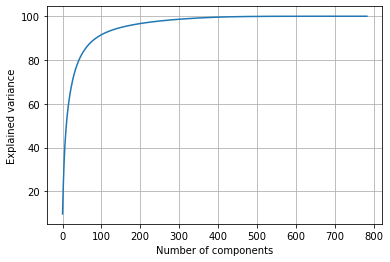

In [2]:
# normalize data before PCA
train_images = train_images.astype('float32') / 255
test_images = test_images.astype('float32') / 255

# apply PCA once to
# select the best number of components
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca_784 = PCA(n_components=784)
pca_784.fit(train_images)

plt.grid()
plt.plot(np.cumsum(pca_784.explained_variance_ratio_ * 100))
plt.xlabel('Number of components')
plt.ylabel('Explained variance')

In [4]:
# apply PCA again with 100 components
# about 90% of the variability retained
# transformation is applied to both
# train and test sets
pca_100 = PCA(n_components=100)
pca_100.fit(train_images)
train_images_reduced = pca_100.transform(train_images)
test_images_reduced = pca_100.transform(test_images)

# verify shape after PCA
print("Train images shape:", train_images_reduced.shape)
print("Test images shape: ", test_images_reduced.shape)

# get exact variability retained
print("\nVar retained (%):", 
      np.sum(pca_100.explained_variance_ratio_ * 100))

Train images shape: (60000, 100)
Test images shape:  (10000, 100)

Var retained (%): 91.41903


In [5]:
# convert labels to a one-hot vector
from tensorflow.keras.utils import to_categorical

train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

# define network architecture
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import InputLayer
from tensorflow.keras.layers import Dense

MLP = Sequential()
MLP.add(InputLayer(input_shape=(100, ))) # input layer
MLP.add(Dense(64, activation='relu')) # hidden layer 1
MLP.add(Dense(32, activation='relu')) # hidden layer 2
MLP.add(Dense(10, activation='softmax')) # output layer

# optimization
MLP.compile(loss='categorical_crossentropy',
            optimizer='adam',
            metrics=['accuracy'])

# train (fit)
history = MLP.fit(train_images_reduced, train_labels, 
                  epochs=20, batch_size=128, verbose=0,
                  validation_split=0.15)

# evaluate performance on test data
test_loss, test_acc = MLP.evaluate(test_images_reduced, test_labels,
                                         batch_size=128,
                                         verbose=0)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

2022-09-17 11:54:27.748353: W tensorflow/core/common_runtime/base_collective_executor.cc:216] BaseCollectiveExecutor::StartAbort Invalid argument: logits and labels must be broadcastable: logits_size=[128,10] labels_size=[1280,2]
	 [[{{node loss/dense_5_loss/softmax_cross_entropy_with_logits}}]]


InvalidArgumentError:  logits and labels must be broadcastable: logits_size=[128,10] labels_size=[1280,2]
	 [[node loss/dense_5_loss/softmax_cross_entropy_with_logits (defined at Users/xiaochuan.yi/opt/anaconda3/envs/tensorflow_env/lib/python3.7/site-packages/tensorflow_core/python/framework/ops.py:1751) ]] [Op:__inference_distributed_function_1002]

Function call stack:
distributed_function


In [7]:
# convert labels to a one-hot vector
from tensorflow.keras.utils import to_categorical

train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

# define network architecture
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import InputLayer
from tensorflow.keras.layers import Dense

MLP = Sequential()
MLP.add(InputLayer(input_shape=(100, ))) # input layer
MLP.add(Dense(64, activation='relu')) # hidden layer 1
MLP.add(Dense(32, activation='relu')) # hidden layer 2
MLP.add(Dense(10, activation='softmax')) # output layer

# optimization
MLP.compile(loss='categorical_crossentropy',
            optimizer='adam',
            metrics=['accuracy'])

# train (fit)
history = MLP.fit(train_images_reduced, train_labels, 
                  epochs=20, batch_size=128, verbose=0,
                  validation_split=0.15)

# evaluate performance on test data
test_loss, test_acc = MLP.evaluate(test_images_reduced, test_labels,
                                         batch_size=128,
                                         verbose=0)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

2022-09-17 13:43:36.012929: W tensorflow/core/common_runtime/base_collective_executor.cc:216] BaseCollectiveExecutor::StartAbort Invalid argument: logits and labels must be broadcastable: logits_size=[128,10] labels_size=[5120,2]
	 [[{{node loss/dense_11_loss/softmax_cross_entropy_with_logits}}]]


InvalidArgumentError:  logits and labels must be broadcastable: logits_size=[128,10] labels_size=[5120,2]
	 [[node loss/dense_11_loss/softmax_cross_entropy_with_logits (defined at Users/xiaochuan.yi/opt/anaconda3/envs/tensorflow_env/lib/python3.7/site-packages/tensorflow_core/python/framework/ops.py:1751) ]] [Op:__inference_distributed_function_2690]

Function call stack:
distributed_function
